# Fit a stress–strain curve with rotating polygons

This tutorial builds a **3×3 square grid**, then optimizes its polygon shapes. The mechanics live in `rotating_polygons`; the notebook assembles geometry, prescribed degrees of freedom, initialization, potential, solver, objective, restrictions, and optimization in order.

Install from the repository root with `python -m pip install -e ".[notebook]"`, and select that environment as the kernel. All numbers below use consistent nondimensional units. The target is a synthetic attainable curve, not experimental data.

This is tutorial 1. Continue with [boundary conditions and individual DoFs](02_boundary_conditions.ipynb), [different design objectives](03_optimization_objectives.ipynb), and [optimizing spring constants](04_optimize_spring_constants.ipynb).

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from rotating_polygons import (
    square_grid,
    compression_boundary,
    initialize,
    PotentialParameters,
    make_potential,
    QuasistaticOptions,
    make_quasistatic_solver,
    make_stress_measurement,
    stress_curve_loss,
    make_shape_constraint,
    minimize_design,
    VerletOptions,
    make_verlet_solver,
)
from rotating_polygons.plotting import plot_geometry

jax.config.update("jax_enable_x64", True)  # Set precision before constructing any model arrays.
%matplotlib inline

## 1. Geometry

Each polygon has center coordinates and one angle. Its corners are local **arm vectors**, stored in counterclockwise order. Bonds connect vertex indices. The generated squares are diamond-oriented; initially every ligament has length 0.2.

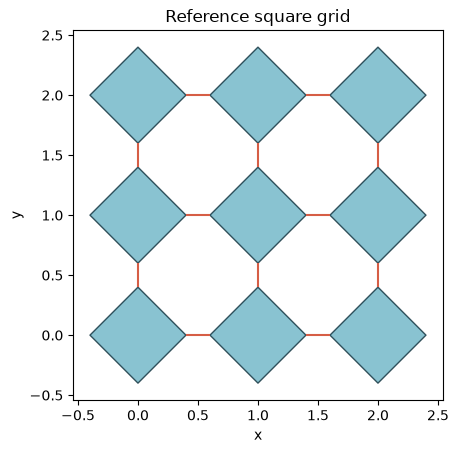

9 polygons, 12 hinges


In [2]:
geometry = square_grid(nx=3, ny=3, spacing=1.0, hinge_gap=0.2)  # Nine squares; finite hinge gaps.
# Polygon IDs run left-to-right along each row, starting with the bottom row.
# geometry.reference_state has shape (9, 3), with columns x, y, theta.
# geometry.vertices has shape (36, 2), with four local arm vectors per polygon.
plot_geometry(geometry)  # Draw the initial outlines and the connecting ligaments.
plt.title("Reference square grid")
plt.show()
print(f"{geometry.n_polygons} polygons, {geometry.n_bonds} hinges")

## 2. Prescribed degrees of freedom

Clamp the bottom row and move the top row downward. `fixed_mask=True` means prescribed, including moving coordinates. The grip-center distance defines the strain gauge length. The default reference width is the initial polygon bounding-box width; it stays fixed throughout optimization.

In [3]:
boundary = compression_boundary(geometry)  # Clamp both grip rows; move only the top y coordinates.
# fixed_mask[i, 0/1/2] controls polygon i's x/y/theta coordinate.
# True with zero strain_direction means fixed in place; True with a nonzero
# direction means prescribed motion. False means the solver finds that coordinate.
# To change a single entry or compare supports, see tutorial 02.
print(f"Gauge height: {boundary.height:g}; reference width: {boundary.width:g}")
print(f"Free coordinates: {boundary.free_indices.size}")

Gauge height: 2; reference width: 2.8
Free coordinates: 9


## 3. Shape variables and initialization

Two shared parameters move the upper vertex sideways and the right vertex vertically on every polygon. Small initial offsets break exact symmetry, which can otherwise give a vanishing shape gradient. For independent shapes, replace this map with `geometry.vertices + offsets.reshape((-1, 2))`.

Every candidate is reinitialized: hinge lengths, endpoint angles, and contact openings are computed from its own undeformed geometry.

In [4]:
def vertices_from_parameters(parameters):
    offsets = jnp.zeros((4, 2))  # One 2D offset for each vertex: right, up, left, down.
    offsets = offsets.at[1, 0].set(parameters[0])  # Move the upper vertex in x.
    offsets = offsets.at[0, 1].set(parameters[1])  # Move the right vertex in y.
    # Repeat the same shape change on every polygon; the centers are unchanged.
    return geometry.vertices + jnp.tile(offsets, (geometry.n_polygons, 1))


def initialize_design(parameters):
    # Recompute rest lengths and endpoint angles for THIS candidate geometry.
    return initialize(geometry, vertices_from_parameters(parameters))


initial_parameters = jnp.array([0.025, -0.02])  # The TWO numbers the outer optimizer can change.
initial_reference = initialize_design(initial_parameters)  # Rest data for the initial candidate.

## 4. Material parameters and potential

The default finite-hinge energy includes axial extension, changes of both endpoint angles, relative rotation, and angular contact. Contact is a local corner-closure penalty, not general polygon collision detection. Material coefficients remain fixed here; only shapes are optimized.

In [5]:
coefficients = PotentialParameters(
    stretching=1.0,  # Axial-extension stiffness: fixed throughout this shape-only optimization.
    shearing=0.1,  # Endpoint-angle shear stiffness.
    bending=0.02,  # Stiffness against relative polygon rotation.
    contact=40.0,  # Penalty for closed/overlapping connected-corner angles.
)
potential = make_potential(geometry, coefficients, model="finite_hinge")  # Scalar E(q, reference).
# For ACTIVE material variables use MechanicalParameters and
# make_parameterized_potential instead: tutorial 04 shows the complete workflow.

## 5. Quasistatic compression

Strains are absolute values, so the same API supports unloading cycles. Each equilibrium starts from the previous one. `check_convergence()` rejects failed steps. Implicit design derivatives assume a converged, locally nonsingular equilibrium; branch switching near buckling needs separate care.

In [6]:
strains = jnp.linspace(0.0, 0.04, 7)  # Seven absolute strains from rest to 4% compression.
options = QuasistaticOptions(
    method="bfgs",  # Inner minimizer: relax free polygon coordinates at each strain.
    tolerance=1e-9,  # Required norm of the force/torque residual on free coordinates.
    max_iterations=500,  # Maximum INNER iterations for each individual equilibrium.
)
simulate = make_quasistatic_solver(geometry, boundary, potential, options)  # Construct once.
measure_stress = make_stress_measurement(potential, boundary, thickness=1.0)  # Force / area.
initial_solution = simulate(initial_reference, strains).check_convergence()  # Warm-start each step.
initial_stress = measure_stress(
    initial_solution.states, initial_reference
)  # Use matching rest data.
print("Largest free-force residual:", float(initial_solution.residuals.max()))

Largest free-force residual: 5.272825061877765e-10


## 6. Target curve and objective

Generate an attainable target from another admissible shape. Its parameters are **not** provided to the optimizer. Replace `target_stress` with desired values sampled at `strains` for your own problem, for example from a CSV using `np.interp`.

Positive nominal stress is the compressive reaction divided by the reference width and thickness. It differs from the unnormalized “stress” in the original notebooks. The objective is mean squared error normalized by the largest target stress.

In [7]:
target_reference = initialize_design(jnp.array([0.10, 0.07]))  # A second, feasible shape.
target_solution = simulate(
    target_reference, strains
).check_convergence()  # Generate synthetic data.
target_stress = measure_stress(target_solution.states, target_reference)  # One value per strain.
# For experimental data, replace target_stress with your measured values;
# interpolate them onto strains and use the SAME force/stress and sign conventions.
loss = stress_curve_loss(
    simulate,
    initialize_design,
    measure_stress,
    strains,
    target_stress,
)  # Returns loss(parameters): normalized mean squared stress error.
print("Initial normalized MSE:", float(loss(initial_parameters)))

Initial normalized MSE: 0.0897079703616269


## 7. Manufacturing restrictions

All constraint margins must be **nonnegative**. Enforce minimum edge length, positive corner turning sine, and nonzero rest ligament length. These restrictions apply to the reference geometry; they do not guarantee collision-free deformed trajectories.

In [8]:
bounds = [
    (-0.12, 0.12),
    (-0.12, 0.12),
]  # One lower/upper bound per shape variable, in length units.
constraint = make_shape_constraint(
    geometry,
    vertices_from_parameters,  # Apply geometric restrictions AFTER mapping variables to vertices.
    min_edge_length=0.2,  # Polygon edges must not collapse.
    min_corner_sine=0.25,  # Keep convex corners away from nearly collinear configurations.
    min_ligament_length=0.08,  # Finite hinges need a nonzero rest length.
)
# Each returned margin must be >= 0; negative means an infeasible design.
print("Smallest initial constraint margin:", float(constraint(initial_parameters).min()))

Smallest initial constraint margin: 0.12099751242241776


## 8. Optimize and inspect the result

SciPy SLSQP drives the outer optimization using exact JAX gradients and constraint Jacobians. The first call includes compilation. Check both optimizer status and equilibrium residuals; fitting a curve does not imply unique shape recovery.

In [9]:
result = minimize_design(
    loss,  # Callable that accepts the design vector and returns ONE scalar.
    initial_parameters,  # Initial values; their shape determines the number of design variables.
    bounds=bounds,  # Box bounds on that same vector.
    constraints=[constraint],  # A list of additional nonnegative-margin restrictions.
    maxiter=40,  # Maximum OUTER design iterations, distinct from inner equilibrium iterations.
    tol=1e-9,  # Outer objective/optimality tolerance; separate from force-residual tolerance.
)
if not result.success:  # Never interpret an optimizer failure as a completed design.
    raise RuntimeError(result.message)
optimized_reference = initialize_design(
    result.parameters
)  # Rebuild rest data for the final design.
optimized_solution = simulate(
    optimized_reference, strains
).check_convergence()  # Verify every step.
optimized_stress = measure_stress(optimized_solution.states, optimized_reference)
print(result.message)
print(f"Normalized MSE: {result.initial_loss:.6g} -> {result.fun:.6g}")
print("Optimized parameters:", np.asarray(result.parameters))
print("Maximum constraint violation:", result.max_constraint_violation)

Optimization terminated successfully
Normalized MSE: 0.089708 -> 1.70921e-10
Optimized parameters: [0.09995045 0.06951482]
Maximum constraint violation: 0.0


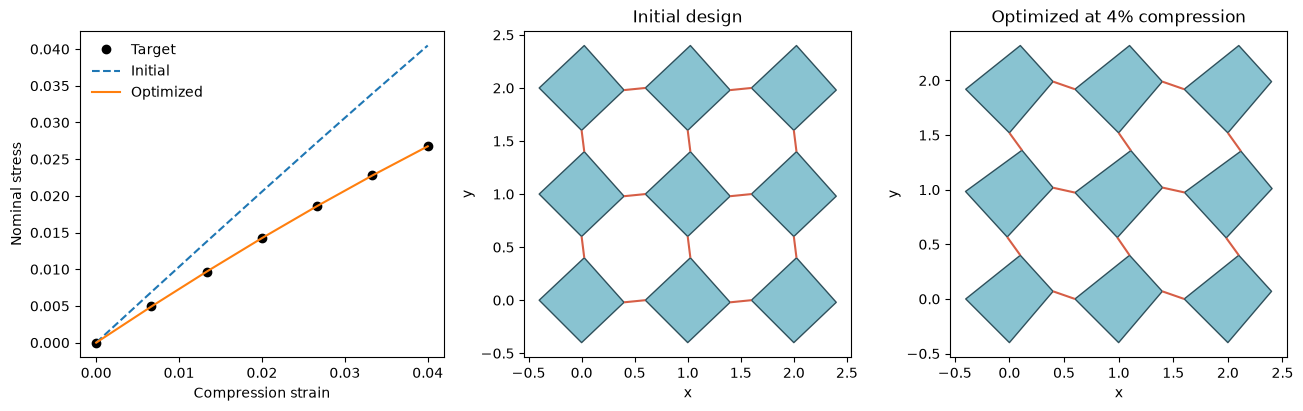

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
axes[0].plot(strains, target_stress, "ko", label="Target")
axes[0].plot(strains, initial_stress, "--", label="Initial")
axes[0].plot(strains, optimized_stress, label="Optimized")
axes[0].set(xlabel="Compression strain", ylabel="Nominal stress")
axes[0].legend(frameon=False)
plot_geometry(geometry, vertices=initial_reference.vertices, ax=axes[1])
axes[1].set_title("Initial design")
plot_geometry(
    geometry, optimized_solution.states[-1], vertices=optimized_reference.vertices, ax=axes[2]
)
axes[2].set_title("Optimized at 4% compression")
plt.show()

## 9. Swap the solver for velocity Verlet

Geometry, boundary conditions, initialization, and potential are reused. The time step and loading rate now matter. The effective masses and rotational inertias below are demonstration values; choose them for your system and check timestep convergence. Damping dissipates energy while the moving grips also perform work.

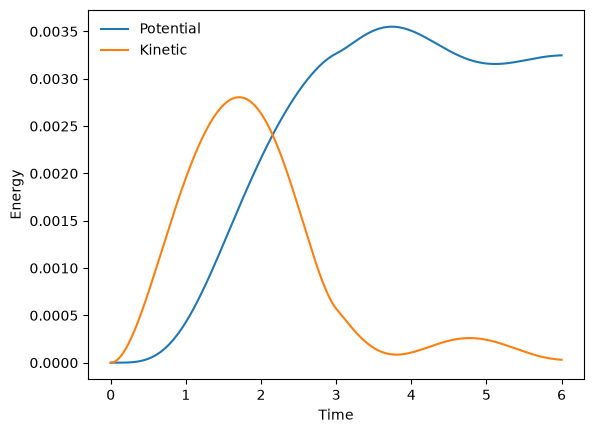

In [11]:
dynamic_options = VerletOptions(
    time_step=0.002, damping=0.5
)  # Time spacing and velocity decay rate.
integrate = make_verlet_solver(
    geometry,
    boundary,
    potential,  # Reuse the same geometry, supports, and energy.
    masses=1.0,
    inertias=0.1,  # Effective translational masses and rotational inertias.
    options=dynamic_options,
)
times = jnp.arange(3001) * dynamic_options.time_step  # 3000 steps, including an initial sample.
ramp = jnp.minimum(times / 3.0, 1.0)  # Ramp for three time units, then hold the grip position.
dynamic_strains = 0.04 * (3 * ramp**2 - 2 * ramp**3)  # Smooth start/end of the compression ramp.
dynamics = integrate(
    optimized_reference, dynamic_strains
)  # Integrate, rather than minimize energy.
plt.plot(dynamics.times, dynamics.potential_energies, label="Potential")
plt.plot(dynamics.times, dynamics.kinetic_energies, label="Kinetic")
plt.xlabel("Time")
plt.ylabel("Energy")
plt.legend(frameon=False)
plt.show()

## Continue with the other worked examples

- [02 — Boundary conditions](02_boundary_conditions.ipynb): fixed/sliding grips, an individual fixed x/y/rotation, a nonzero prescribed angle, and shear loading.
- [03 — Different objectives](03_optimization_objectives.ipynb): target a secant stiffness or redistribute support forces; change objective weights and solver tolerances.
- [04 — Spring constants](04_optimize_spring_constants.ipynb): keep the shape fixed, optimize a shared or grouped spring stiffness, and understand physical versus logarithmic parameters.

The [example guide](README.md) maps each notebook to its Python script. The [module guide](../docs/modules.md) explains the underlying API.